# EMG ↔ joint angles: how does muscle activity relate to movement?

This notebook asks one question: **which parts of the movement can the sEMG envelope explain, and with what delay?**

Plan:
1. Turn the raw EMG into a slow "activity" signal (band-pass → RMS envelope → log), at 100 Hz, aligned with the joint angles.
2. Look at it next to the angles for one task.
3. Correlate every channel with every joint, for **position**, **signed velocity** and **speed** (|velocity|).
4. Sweep the time lag between EMG and movement: EMG should *lead* (electromechanical delay).
5. Decode angles and velocities from the envelopes with ridge regression (cross-validated).
6. Test generalisation to an unseen task (leave-one-task-out).
7. CCA: the main shared "modes" between the 16 channels and the 20 joints.

Data: the mini dataset in `~/emg2pose_dataset_mini` (1 user, 15 tasks, both hands). We use the **right hand** only.

## Setup

**Locally:** run `uv sync --extra cpu` in the repo root and pick the **semg2pose** kernel. The cell below does nothing.

**On Colab:** select *Runtime → Change runtime type → Runtime version 2026.07* (Python 3.12), optionally with a T4 GPU.
Run the cell below once; when it says so, do *Runtime → Restart session* and run the notebook from the top again.

In [1]:
# Colab only: clone semg2pose (with the emg2pose submodule) and install it. Locally this does nothing.
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    if not (3, 10) <= sys.version_info[:2] < (3, 13):
        raise RuntimeError("Select Runtime > Change runtime type > Runtime version 2026.07 "
                           "(Python 3.12), then run this cell again.")
    REPO_DIR = Path("/content/semg2pose")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--recurse-submodules",
                        "https://github.com/eljoserass/semg2pose.git", str(REPO_DIR)], check=True)
    try:
        import semg2pose  # noqa: F401  (installed in a previous run + restart)
        print("semg2pose is installed, continue.")
    except ImportError:
        subprocess.run(["bash", str(REPO_DIR / "scripts" / "colab_setup.sh")], check=True,
                       env={**os.environ, "PYTHON": sys.executable})
        print("Installed. Now: Runtime > Restart session, then run the notebook from the top.")
else:
    print("Local kernel:", sys.executable)

Local kernel: /home/jose/Documents/projects/neuromatch/semg2pose/.venv/bin/python


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.cross_decomposition import CCA

from semg2pose.data import FS, JOINT_NAMES, download_mini_dataset, load_session
from semg2pose.signals import log_envelope

DATASET_DIR = download_mini_dataset()

STEP = 20          # downsampling factor -> 100 Hz
FS_LOW = FS // STEP
plt.rcParams["figure.dpi"] = 100


Dataset already downloaded: /home/jose/emg2pose_dataset_mini


## 1. Preprocessing: envelope, velocity, mask

For each right-hand session:

- **EMG** → band-pass 20–450 Hz (almost all the power is there, see `motor_units_zoom.ipynb`) → square → 50 ms moving average → square root (= moving RMS) → `log(x + 1)` (compresses the large bursts) → keep one sample every 20 → **100 Hz**.
- **Angles** → same 100 Hz grid. **Angular velocity** with a Savitzky–Golay derivative (fits a local quadratic over 110 ms, so it does not amplify noise like a plain `diff`).
- **Mask**: tracking failures (all angles = 0) are removed. The derivative near a failure is garbage, so we also drop 60 ms on each side of every failure.

In [3]:
def envelope(emg):
    # 20-450 Hz band-pass -> 50 ms moving RMS -> log(1 + x)  (semg2pose.signals.log_envelope)
    return log_envelope(emg, band=(20, 450), window_s=0.050)


sessions = []
for path in sorted(DATASET_DIR.glob("*_right.hdf5")):
    emg, angles, ok, meta = load_session(path)
    env = envelope(emg)[::STEP]
    ang = angles[::STEP]
    ok = ok[::STEP]
    vel = signal.savgol_filter(ang, 11, 2, deriv=1, delta=1 / FS_LOW, axis=0)  # rad/s
    # erode the valid mask by 6 samples (60 ms) around each failure
    good = ~np.convolve(~ok, np.ones(13), mode="same").astype(bool)
    sessions.append({"stage": meta["stage"], "env": env, "ang": ang, "vel": vel, "ok": good})

summary = pd.DataFrame([{"stage": s["stage"], "minutes": len(s["ok"]) / FS_LOW / 60,
                         "valid %": 100 * s["ok"].mean()} for s in sessions]).round(1)
print(f"{len(sessions)} right-hand sessions, {summary.minutes.sum():.1f} min in total")
summary

15 right-hand sessions, 17.8 min in total


,stage,minutes,valid %
0,HandClawGraspFlicks,1.0,84.2
1,ShakaVulcanPeace,1.0,88.4
2,HookEmHornsOKScissors,1.0,94.7
3,TwoHandedFreeStyle,3.9,65.8
4,unconstrained,0.9,60.0
5,OneHandedFreeStyle,0.8,49.8
6,ThumbsUpDownThumbRotationsCWCCWP,1.2,50.5
7,CountingUpDownFaceSideAway,1.0,95.5
8,ThumbsSwipesWholeHand,1.0,90.0
9,FingerWigglingSpreading,1.0,98.1


## 2. A first look: envelopes next to angles

`HandClawGraspFlicks`: repeated claws, grasps and flicks. Top: the envelope of 4 channels (z-scored). Middle: 3 finger flexion angles. Bottom: their velocities.

Look at *when* the envelope rises: at the start of a closing/opening movement, i.e. around the **velocity** peaks, not during the whole time the hand stays closed.

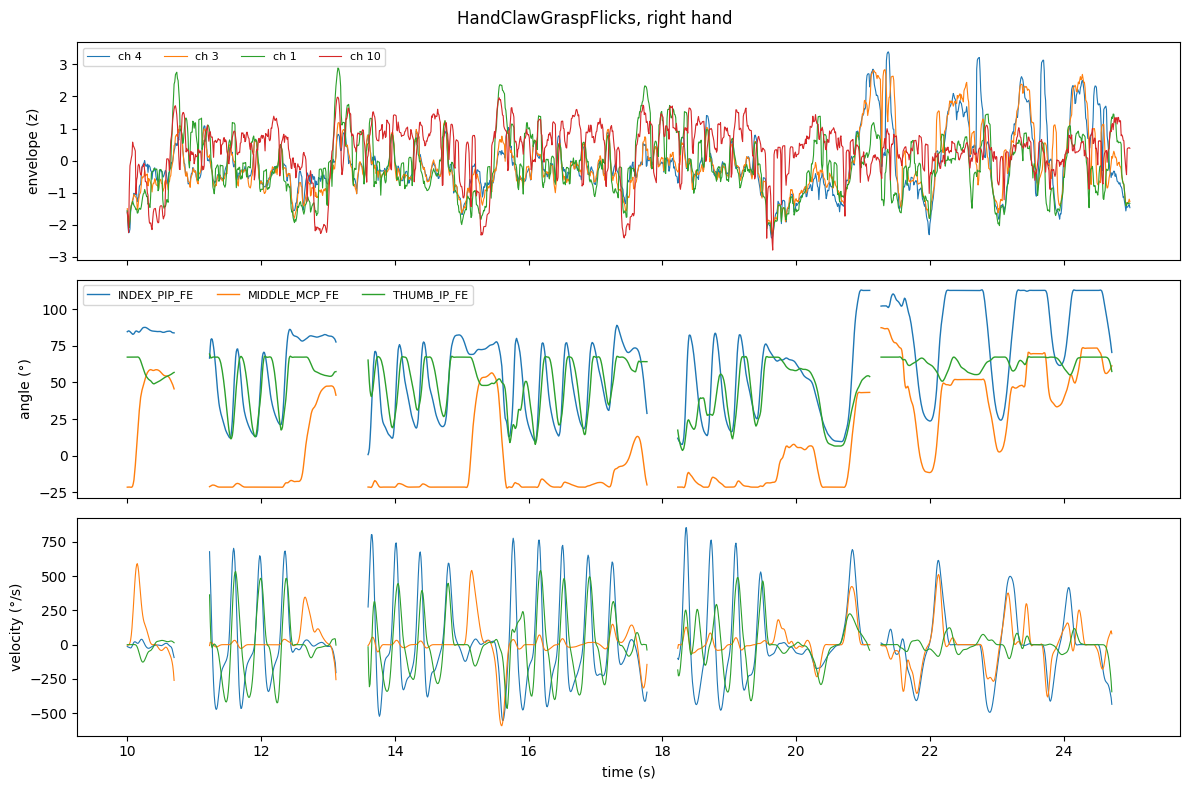

In [4]:
ex = next(s for s in sessions if s["stage"] == "HandClawGraspFlicks")
t = np.arange(len(ex["ok"])) / FS_LOW
sel = (t >= 10) & (t < 25)
show_ch = np.argsort(ex["env"].std(axis=0))[-4:]  # 4 most variable channels
show_j = [JOINT_NAMES.index(n) for n in ["INDEX_PIP_FE", "MIDDLE_MCP_FE", "THUMB_IP_FE"]]

fig, axs = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for c in show_ch:
    e = ex["env"][:, c]
    axs[0].plot(t[sel], (e[sel] - e.mean()) / e.std(), lw=0.8, label=f"ch {c}")
axs[0].set_ylabel("envelope (z)")
axs[0].legend(ncol=4, fontsize=8)
for j in show_j:
    a = np.where(ex["ok"], np.degrees(ex["ang"][:, j]), np.nan)
    v = np.where(ex["ok"], np.degrees(ex["vel"][:, j]), np.nan)
    axs[1].plot(t[sel], a[sel], lw=1, label=JOINT_NAMES[j])
    axs[2].plot(t[sel], v[sel], lw=0.8, label=JOINT_NAMES[j])
axs[1].set_ylabel("angle (°)")
axs[1].legend(ncol=3, fontsize=8)
axs[2].set_ylabel("velocity (°/s)")
axs[2].set_xlabel("time (s)")
fig.suptitle("HandClawGraspFlicks, right hand")
plt.tight_layout()
plt.show()

## 3. Channel × joint correlations

For each session we correlate every channel envelope with every joint (valid samples only), then average the 15 per-session matrices. Three targets:

- **position** (angle),
- **signed velocity** (flexing vs extending),
- **speed** = |velocity| (moving vs still).

All at zero lag here; the lag comes in section 4.

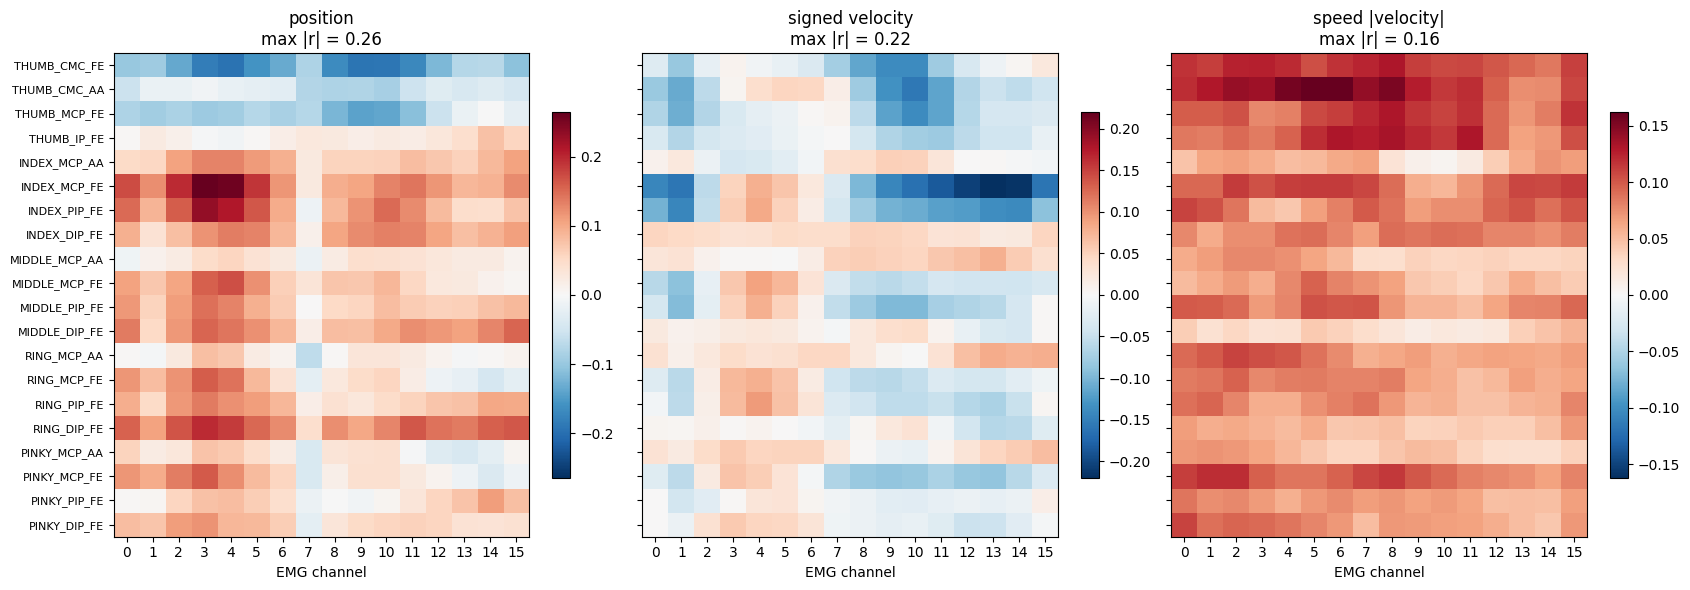

,position,signed velocity,speed |velocity|
mean |r|,0.076,0.047,0.076
max |r|,0.264,0.220,0.162


In [5]:
def corr_matrix(X, Y):
    # Pearson correlation between every column of X (T, a) and every column of Y (T, b) -> (a, b)
    Xz = (X - X.mean(0)) / (X.std(0) + 1e-12)
    Yz = (Y - Y.mean(0)) / (Y.std(0) + 1e-12)
    return Xz.T @ Yz / len(X)


targets = {"position": lambda s: s["ang"], "signed velocity": lambda s: s["vel"],
           "speed |velocity|": lambda s: np.abs(s["vel"])}
mean_corr = {}
for name, fn in targets.items():
    mats = [corr_matrix(s["env"][s["ok"]], fn(s)[s["ok"]]) for s in sessions]
    mean_corr[name] = np.mean(mats, axis=0)

fig, axs = plt.subplots(1, 3, figsize=(17, 6), sharey=True)
for ax, (name, M) in zip(axs, mean_corr.items()):
    lim = np.abs(M).max()
    im = ax.imshow(M.T, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(16))
    ax.set_xlabel("EMG channel")
    ax.set_title(f"{name}\nmax |r| = {lim:.2f}")
    plt.colorbar(im, ax=ax, fraction=0.04)
axs[0].set_yticks(range(20), JOINT_NAMES, fontsize=8)
plt.tight_layout()
plt.show()

pd.DataFrame({name: [np.abs(M).mean(), np.abs(M).max()] for name, M in mean_corr.items()},
             index=["mean |r|", "max |r|"]).round(3)

**How to read it.**

- **Position**: the strongest single cells are channels ~2–5 with index/middle/ring MCP and PIP flexion (r ≈ 0.2–0.26). That side of the ring is over the finger flexors (`motor_units_zoom.ipynb` put the flexion peak near channel 3.5).
- **Signed velocity** splits the ring: channels ~3–5 are positive with finger FE velocity and channels ~9–14 are negative. These are the two sides of the wrist, agonist vs antagonist.
- **Speed** is positive for almost every channel and joint: any movement needs muscle activity, whatever its direction. But the effect is diffuse (max r 0.16).

All values are small. One envelope explains at most ~7 % of the variance of one joint. The information is spread over channels, so a decoder has to combine them (section 5).

Averaging all channels into one "total EMG" signal cancels the signed-velocity structure, so keep the channels separate.

## 4. Lag sweep: does the EMG lead the movement?

Muscles are activated electrically before they produce force and move the joint (**electromechanical delay**, typically tens of ms). We shift the envelope relative to the movement: **positive lag = EMG at time t − lag is compared with movement at time t**, i.e. EMG leads.

Summary per lag (same metric as section 3: r averaged over the 15 sessions, then |r| averaged over pairs):
- position and signed velocity: mean |r| over all 16 × 20 channel–joint pairs,
- **hand speed** = norm of the 20-joint velocity vector, correlated with each channel.

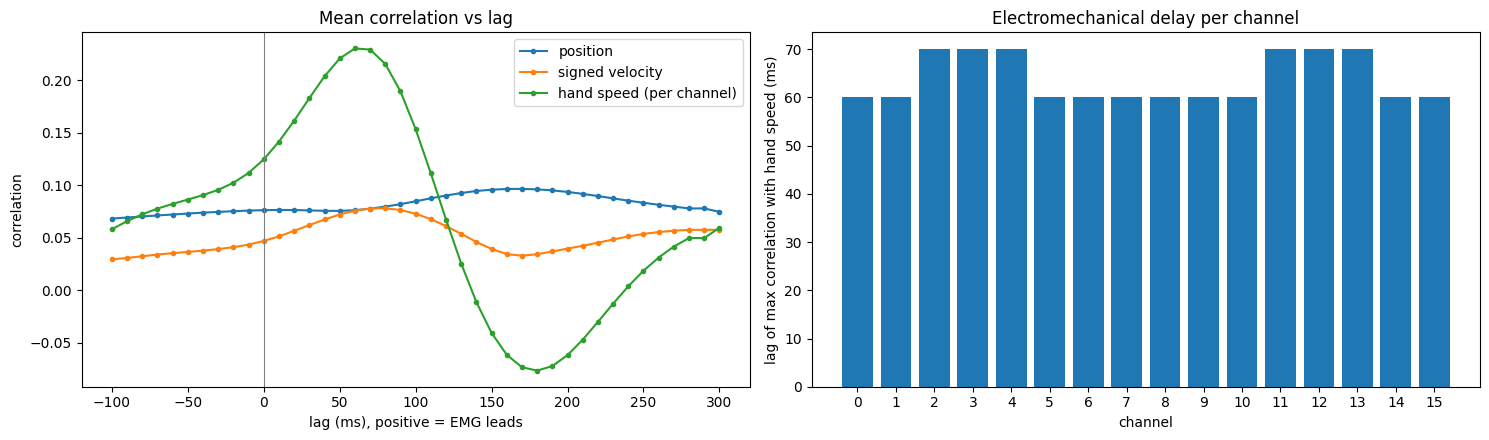

position                   peak r = 0.097 at +170 ms
signed velocity            peak r = 0.078 at +80 ms
hand speed (per channel)   peak r = 0.230 at +60 ms
Per-channel peak lag (ms): [60 60 70 70 70 60 60 60 60 60 60 70 70 70 60 60]  median: 60.0


In [6]:
LAGS_MS = np.arange(-100, 301, 10)


def lagged_pairs(s, lag):
    # Returns (env at t - lag, index t) for valid t; lag in samples (positive = EMG leads)
    T = len(s["ok"])
    t_idx = np.arange(max(lag, 0), T + min(lag, 0))
    src = t_idx - lag
    keep = s["ok"][t_idx] & s["ok"][src]
    return s["env"][src[keep]], t_idx[keep]


curves = {"position": [], "signed velocity": [], "hand speed (per channel)": []}
per_channel = []  # (n_lags, 16) correlation with hand speed, averaged over sessions
for lag_ms in LAGS_MS:
    lag = int(lag_ms / 1000 * FS_LOW)
    rp, rv, rs = [], [], []
    for s in sessions:
        E, ti = lagged_pairs(s, lag)
        rp.append(corr_matrix(E, s["ang"][ti]))
        rv.append(corr_matrix(E, s["vel"][ti]))
        speed = np.linalg.norm(s["vel"][ti], axis=1, keepdims=True)
        rs.append(corr_matrix(E, speed)[:, 0])
    # same metric as section 3: average r over sessions first, then |.| over channel-joint pairs
    curves["position"].append(np.abs(np.mean(rp, axis=0)).mean())
    curves["signed velocity"].append(np.abs(np.mean(rv, axis=0)).mean())
    per_channel.append(np.mean(rs, axis=0))
    curves["hand speed (per channel)"].append(np.mean(rs))
per_channel = np.array(per_channel)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
for name, values in curves.items():
    ax1.plot(LAGS_MS, values, "o-", ms=3, label=name)
ax1.axvline(0, color="gray", lw=0.8)
ax1.set_xlabel("lag (ms), positive = EMG leads")
ax1.set_ylabel("correlation")
ax1.set_title("Mean correlation vs lag")
ax1.legend()

peak_lag = LAGS_MS[per_channel.argmax(axis=0)]
ax2.bar(range(16), peak_lag, color="tab:blue")
ax2.set_xticks(range(16))
ax2.set_xlabel("channel")
ax2.set_ylabel("lag of max correlation with hand speed (ms)")
ax2.set_title("Electromechanical delay per channel")
plt.tight_layout()
plt.show()

best = {name: (LAGS_MS[int(np.argmax(v))], max(v)) for name, v in curves.items()}
for name, (lag_ms, r) in best.items():
    print(f"{name:26s} peak r = {r:.3f} at {lag_ms:+d} ms")
print("Per-channel peak lag (ms):", peak_lag, " median:", np.median(peak_lag))

## 5. Decoding: ridge regression from lagged envelopes

Correlations look at one channel and one joint at a time. A linear decoder combines all 16 channels and a short history: the features are the envelopes at lags 0, 20, 50, 100, 150 and 200 ms (16 × 6 = 96 features).

Validation: each session is cut into 5 contiguous blocks; we train on 4 and test on the 5th (blocked CV, so neighbouring samples don't leak between train and test). R² per joint, for **position** and for **velocity**.

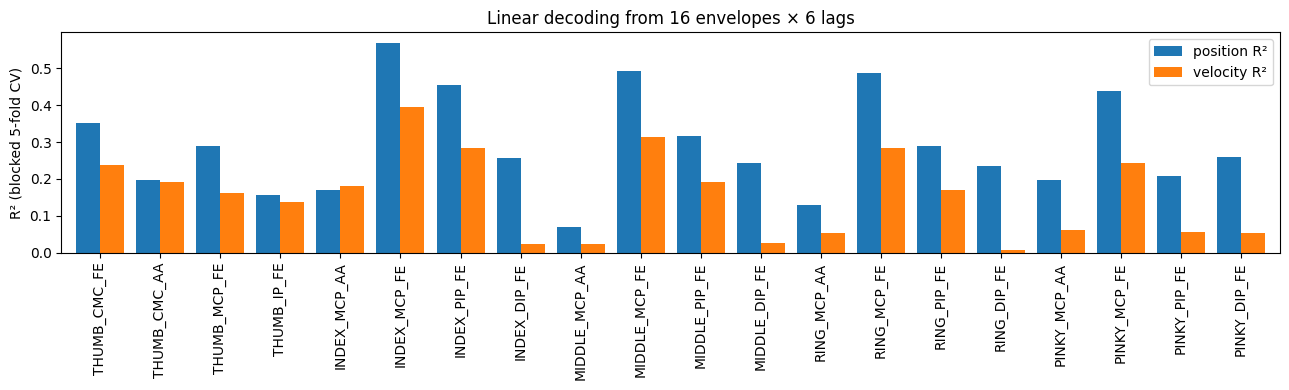

position R²    0.290
velocity R²    0.155


In [7]:
FEATURE_LAGS = [0, 2, 5, 10, 15, 20]  # samples at 100 Hz -> 0..200 ms


def with_lags(X, lags):
    # Past copies of X (pads the start by repeating the first row)
    return np.hstack([X if r == 0 else np.vstack([np.repeat(X[:1], r, axis=0), X[:-r]]) for r in lags])


def stack(target):
    Xs, Ys, folds, stages = [], [], [], []
    for s in sessions:
        X = with_lags(s["env"], FEATURE_LAGS)[s["ok"]]
        Xs.append(X)
        Ys.append(s[target][s["ok"]])
        folds.append(np.arange(len(X)) * 5 // len(X))
        stages.append(np.full(len(X), s["stage"]))
    return np.vstack(Xs), np.vstack(Ys), np.concatenate(folds), np.concatenate(stages)


def ridge_fit_predict(Xtr, Ytr, Xte, lam=10.0):
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-9
    A, B = (Xtr - mu) / sd, (Xte - mu) / sd
    y_mean = Ytr.mean(0)
    W = np.linalg.solve(A.T @ A + lam * np.eye(A.shape[1]), A.T @ (Ytr - y_mean))
    return B @ W + y_mean


def r2(Y, P):
    return 1 - ((Y - P) ** 2).sum(0) / ((Y - Y.mean(0)) ** 2).sum(0)


r2_cv = {}
data = {}
for target in ["ang", "vel"]:
    X, Y, folds, stages = stack(target)
    data[target] = (X, Y, stages)
    P = np.zeros_like(Y)
    for k in range(5):
        tr, te = folds != k, folds == k
        P[te] = ridge_fit_predict(X[tr], Y[tr], X[te])
    r2_cv[target] = r2(Y, P)

res = pd.DataFrame({"position R²": r2_cv["ang"], "velocity R²": r2_cv["vel"]}, index=JOINT_NAMES)
ax = res.plot.bar(figsize=(13, 4), width=0.8)
ax.set_ylabel("R² (blocked 5-fold CV)")
ax.set_title("Linear decoding from 16 envelopes × 6 lags")
plt.tight_layout()
plt.show()
print(res.mean().round(3).to_string())

Combining channels and 200 ms of history helps a lot: position R² is far above what any single correlation gives (r² ≤ 0.07). Position decodes better than velocity: it is slow and smooth, and the flexor/extensor balance tracks it. Velocity is fast, noisy, and its sign depends on a *difference* between opposing muscles, which a linear model on log-envelopes captures only partly.

## 6. Generalisation to an unseen task (leave-one-task-out)

Blocked CV still trains on the same task it tests on. Here we train on 14 tasks and test on the 15th. R² is relative to the variance of the held-out task, so tasks with very little movement (e.g. `unconstrained`, near rest) can give strongly negative R².

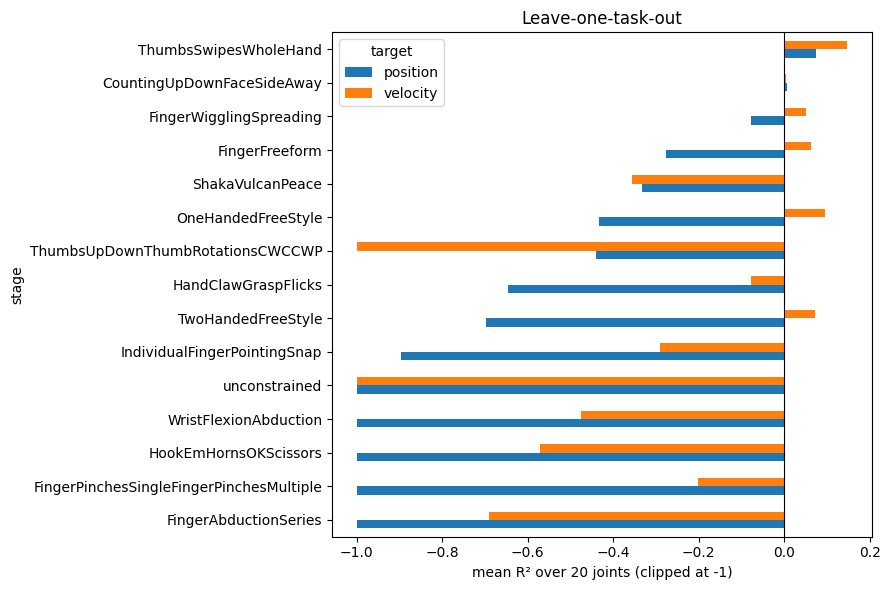

Median over tasks:
 target
position   -0.646
velocity   -0.201


target,position,velocity
stage,,
CountingUpDownFaceSideAway,0.01,0.00
FingerAbductionSeries,-9.10,-0.69
FingerFreeform,-0.28,0.06
FingerPinchesSingleFingerPinchesMultiple,-2.83,-0.20
FingerWigglingSpreading,-0.08,0.05
HandClawGraspFlicks,-0.65,-0.08
HookEmHornsOKScissors,-1.00,-0.57
IndividualFingerPointingSnap,-0.90,-0.29
OneHandedFreeStyle,-0.43,0.10


In [8]:
loto = []
for target in ["ang", "vel"]:
    X, Y, stages = data[target]
    for st in np.unique(stages):
        te = stages == st
        P = ridge_fit_predict(X[~te], Y[~te], X[te])
        loto.append({"stage": st, "target": "position" if target == "ang" else "velocity",
                     "mean R²": r2(Y[te], P).mean()})
loto = pd.DataFrame(loto).pivot(index="stage", columns="target", values="mean R²")

ax = loto.clip(lower=-1).sort_values("position").plot.barh(figsize=(9, 6))
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("mean R² over 20 joints (clipped at -1)")
ax.set_title("Leave-one-task-out")
plt.tight_layout()
plt.show()
print("Median over tasks:\n", loto.median().round(3).to_string())
loto.round(2)

## 7. CCA: shared modes between channels and joints

Canonical correlation analysis finds a weighted sum of channels and a weighted sum of joints that are as correlated as possible, then the next pair (uncorrelated with the first), and so on.

We use envelopes shifted by 60 ms (≈ the lag found above), against **signed velocity** and against **position**. Fit on the first 80 % of every session, report canonical correlations on the last 20 %. To read the modes we plot **structure coefficients** (correlation of each original variable with its canonical variate): channels around the ring, joints as bars.

In [9]:
CCA_LAG = 6  # samples = 60 ms
N_COMP = 3


def cca_split(target):
    Xtr, Ytr, Xte, Yte = [], [], [], []
    for s in sessions:
        E, ti = lagged_pairs(s, CCA_LAG)
        cut = int(0.8 * len(ti))
        Xtr.append(E[:cut]); Ytr.append(s[target][ti[:cut]])
        Xte.append(E[cut:]); Yte.append(s[target][ti[cut:]])
    return np.vstack(Xtr), np.vstack(Ytr), np.vstack(Xte), np.vstack(Yte)


cca_results = {}
for target, label in [("vel", "signed velocity"), ("ang", "position")]:
    Xtr, Ytr, Xte, Yte = cca_split(target)
    mx, sx, my, sy = Xtr.mean(0), Xtr.std(0), Ytr.mean(0), Ytr.std(0)
    cca = CCA(n_components=N_COMP, max_iter=1000).fit((Xtr - mx) / sx, (Ytr - my) / sy)
    U_tr, V_tr = cca.transform((Xtr - mx) / sx, (Ytr - my) / sy)
    U_te, V_te = cca.transform((Xte - mx) / sx, (Yte - my) / sy)
    rho_tr = [np.corrcoef(U_tr[:, k], V_tr[:, k])[0, 1] for k in range(N_COMP)]
    rho_te = [np.corrcoef(U_te[:, k], V_te[:, k])[0, 1] for k in range(N_COMP)]
    struct_x = corr_matrix(Xtr, U_tr)  # (16, N_COMP)
    struct_y = corr_matrix(Ytr, V_tr)  # (20, N_COMP)
    cca_results[label] = (rho_tr, rho_te, struct_x, struct_y)
    print(f"{label:16s} canonical r train: {np.round(rho_tr, 2)}   test: {np.round(rho_te, 2)}")

signed velocity  canonical r train: [0.58 0.43 0.37]   test: [0.51 0.39 0.27]


position         canonical r train: [0.69 0.57 0.55]   test: [0.48 0.46 0.53]


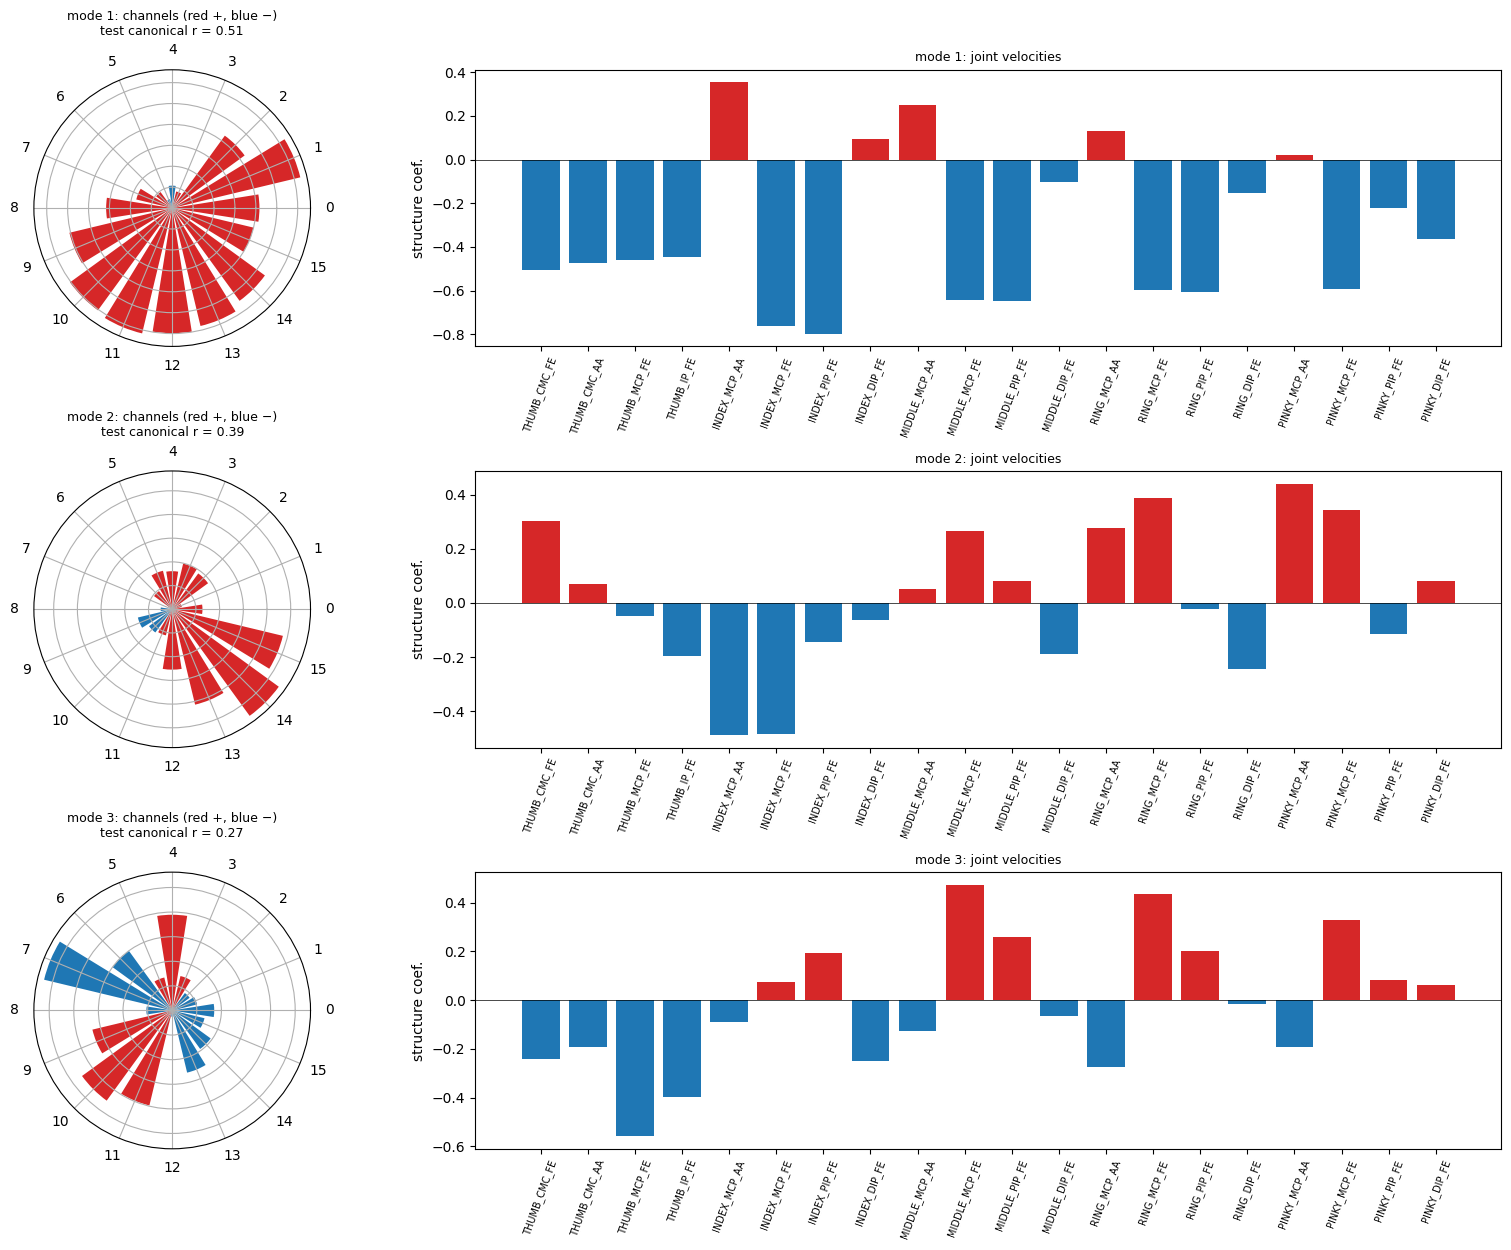

In [10]:
rho_tr, rho_te, struct_x, struct_y = cca_results["signed velocity"]
channel_angle = 2 * np.pi * np.arange(16) / 16
fig = plt.figure(figsize=(16, 4.2 * N_COMP))
for k in range(N_COMP):
    ax = fig.add_subplot(N_COMP, 3, 3 * k + 1, projection="polar")
    w = struct_x[:, k]
    ax.bar(channel_angle, np.abs(w), width=2 * np.pi / 16 * 0.8,
           color=np.where(w > 0, "tab:red", "tab:blue"))
    ax.set_xticks(channel_angle, [str(c) for c in range(16)])
    ax.set_yticklabels([])
    ax.set_title(f"mode {k + 1}: channels (red +, blue −)\ntest canonical r = {rho_te[k]:.2f}", fontsize=9)
    ax = fig.add_subplot(N_COMP, 3, (3 * k + 2, 3 * k + 3))
    v = struct_y[:, k]
    ax.bar(range(20), v, color=np.where(v > 0, "tab:red", "tab:blue"))
    ax.set_xticks(range(20), JOINT_NAMES, rotation=70, fontsize=7)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_ylabel("structure coef.")
    ax.set_title(f"mode {k + 1}: joint velocities", fontsize=9)
plt.tight_layout()
plt.show()

**Reading the modes** (signed velocity, from this run):

- **Mode 1**: all channels with the same sign ↔ almost every FE velocity with the same sign. This is "overall activity level ↔ the whole hand moving in one direction (closing or opening)": a co-activation mode, not a clean flexor-vs-extensor split.
- **Modes 2 and 3** have mixed signs on the ring: different sectors (e.g. ~12–15 vs ~5–9) pair with thumb/index vs middle/ring/pinky patterns. Here the spatial layout starts to say *which* fingers move.

Position gives similar test canonical correlations (~0.5) for its top 3 modes, so posture also has several linearly decodable directions. Test values are below train values, so part of the fit is overfitting.

## 8. Conclusions

The numbers in the next cell are recomputed from this run.

In [11]:
print("Correlation peaks (section 4):")
for name, (lag_ms, r) in best.items():
    print(f"  {name:26s} r = {r:.3f} at {lag_ms:+d} ms")
print(f"Median per-channel lag to hand speed: {np.median(peak_lag):.0f} ms")
print(f"Ridge R² (blocked CV), mean over joints: position {r2_cv['ang'].mean():.3f}, velocity {r2_cv['vel'].mean():.3f}")
print(f"Leave-one-task-out median R²: position {loto['position'].median():.3f}, velocity {loto['velocity'].median():.3f}")
for label, (rho_tr, rho_te, _, _) in cca_results.items():
    print(f"CCA {label:16s} test canonical r: {np.round(rho_te, 2)}")

Correlation peaks (section 4):
  position                   r = 0.097 at +170 ms
  signed velocity            r = 0.078 at +80 ms
  hand speed (per channel)   r = 0.230 at +60 ms
Median per-channel lag to hand speed: 60 ms
Ridge R² (blocked CV), mean over joints: position 0.290, velocity 0.155
Leave-one-task-out median R²: position -0.646, velocity -0.201
CCA signed velocity  test canonical r: [0.51 0.39 0.27]
CCA position         test canonical r: [0.48 0.46 0.53]


Take-aways (numbers from the cell above):

1. **EMG leads movement by ~60 ms.** The correlation with hand speed peaks at a +60–70 ms lag for *every* channel. This is the electromechanical delay, and the cleanest timing signal in the data. Correlation with position peaks later (~170 ms) and is broad: position is the integral of velocity, so it lags further behind the burst that produced it.
2. **Single correlations are weak (|r| ≤ ~0.26), and posture and movement are both in there.** Position has the largest single cells (flexor-side channels ↔ finger flexion). Speed has the most uniform relation. Signed velocity shows the flexor/extensor split around the ring.
3. **Keep channels separate.** The useful structure is *spatial* (which side of the ring), and averaging destroys it.
4. **A linear decoder over channels × lags** reaches R² ≈ 0.29 for position and ≈ 0.16 for velocity *within* tasks. On an **unseen task it fails** (median R² < 0). Each task covers a different region of joint space (see `joint_space_manifold.ipynb`), and the offsets of a linear map don't transfer. This is why the emg2pose baselines are nonlinear and trained on many tasks and users.
5. **Caveats:** 1 user, 1 session per task, 100 Hz log-envelopes only. The fine spectral and spatial structure that the full models use is ignored here.